In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts easier to read
sns.set_theme(style="whitegrid")

# Load the cleaned dataset
file_path = (
    r"D:\Customer-Churn-Analysis\data\processed"
    r"\customer_churn_cleaned.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7032, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print(churn_counts)

# Calculate the percentage of each category
churn_percentages = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("\nChurn percentages:")
print(churn_percentages.round(2))


Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


In [3]:

total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

churn_rate = (
    churned_customers / total_customers
) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print(f"Churn rate: {churn_rate:.2f}%")


Total customers: 7032
Churned customers: 1869
Churn rate: 26.58%


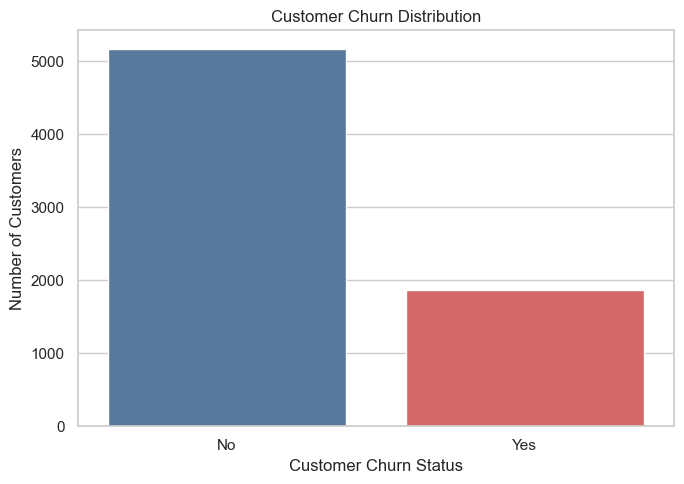

In [29]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette=["#4C78A8", "#E45756"],
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\customer_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [30]:

# Count churned and retained customers within each contract type
contract_counts = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_counts)



Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


In [31]:

contract_churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda series: (series == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(contract_churn_rate.round(2))


Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


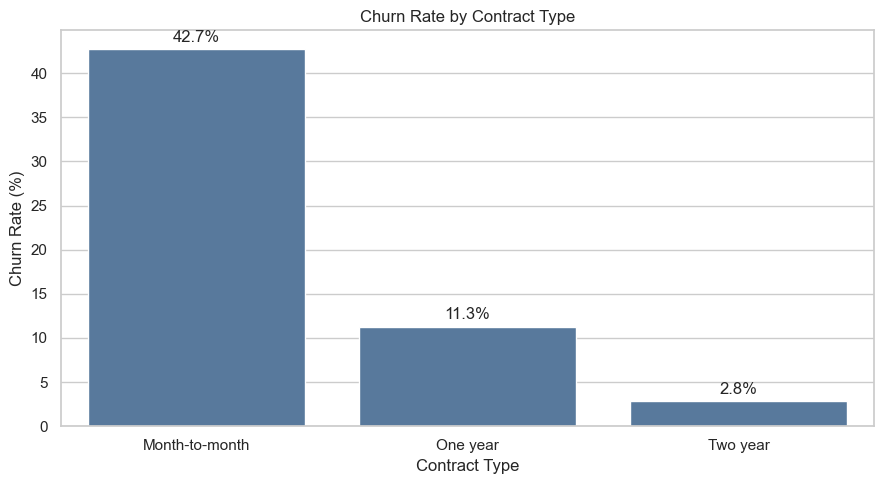

In [32]:

contract_order = contract_churn_rate.index

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=contract_churn_rate.index,
    y=contract_churn_rate.values,
    color="#4C78A8"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

# Display percentages above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\churn_rate_by_contract_type.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [33]:

tenure_summary = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
)

print(tenure_summary.round(2))


       count   mean  median  min  max
Churn                                
No      5163  37.65    38.0    1   72
Yes     1869  17.98    10.0    1   72


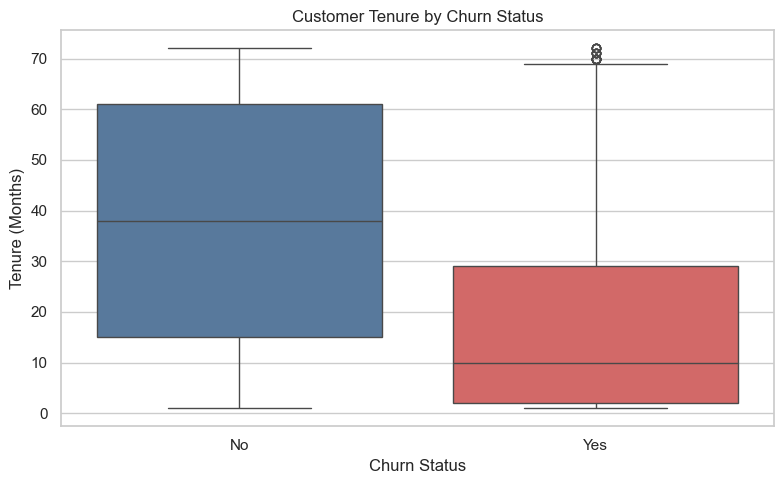

In [34]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    order=["No", "Yes"],
    palette=["#4C78A8", "#E45756"],
    legend=False
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\Customer_Tenure_bu_Churn_status.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [35]:

charges_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median", "std"])
)

print(charges_summary.round(2))


        mean  median    std
Churn                      
No     61.31   64.45  31.09
Yes    74.44   79.65  24.67


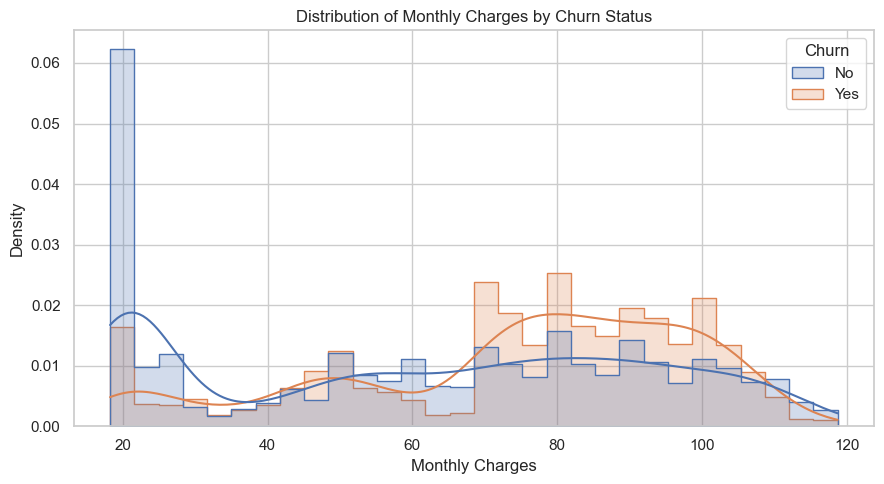

In [36]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Monthly Charges by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")

plt.tight_layout() 
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\Distribution_of_monthly_chargers_by_churn_status.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [37]:

def plot_churn_rate(data, column):
    # Calculate the churn percentage within each category
    rates = (
        data.groupby(column, dropna=False)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    ax = sns.barplot(
        x=rates.index.astype(str),
        y=rates.values,
        color="#4C78A8"
    )

    plt.title(f"Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=25, ha="right")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

    plt.tight_layout()
    plt.show()

    return rates.round(2)


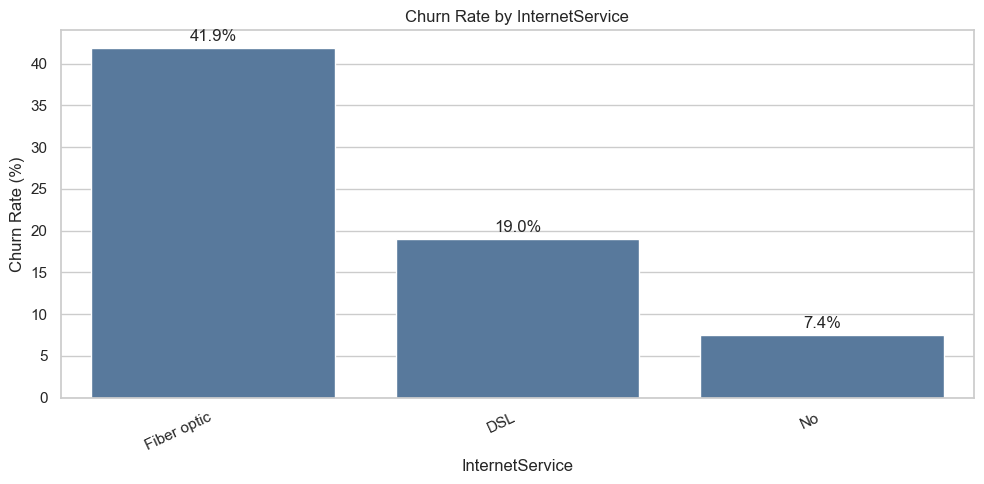

InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64


<Figure size 640x480 with 0 Axes>

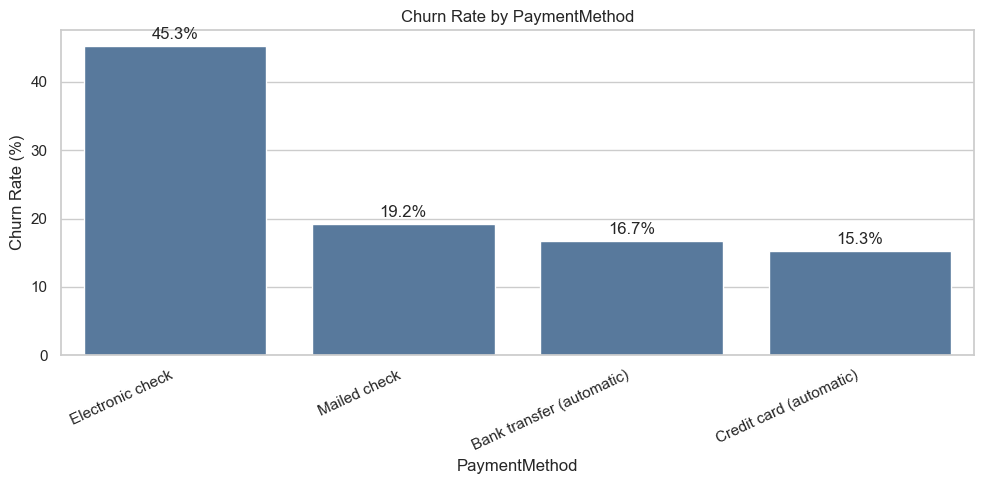

PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64


<Figure size 640x480 with 0 Axes>

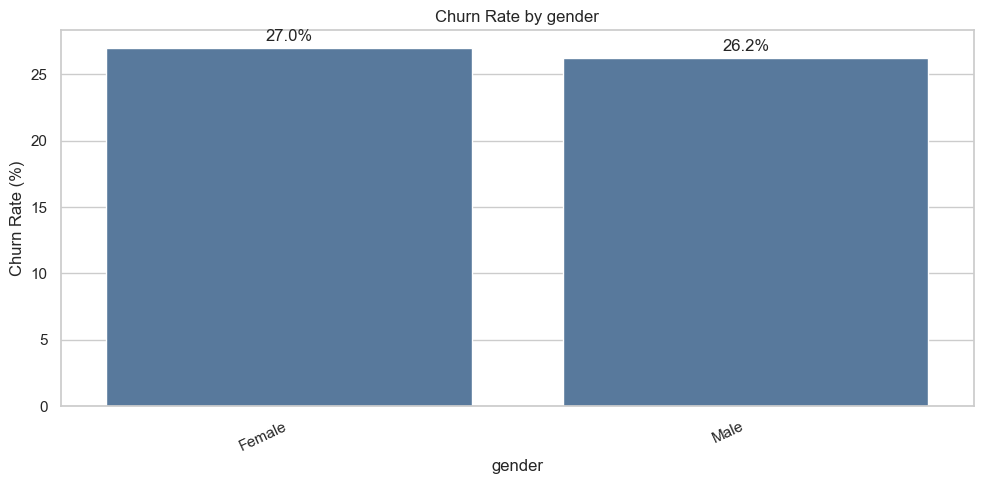

gender
Female    26.96
Male      26.20
Name: Churn, dtype: float64


<Figure size 640x480 with 0 Axes>

In [38]:

internet_churn = plot_churn_rate(df, "InternetService")
print(internet_churn)

plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\churn_rate_by_InternetService.png",
    dpi=300,
    bbox_inches="tight"
)

payment_churn = plot_churn_rate(df, "PaymentMethod")
print(payment_churn)
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\churn_rate_by_PaymentMethod.png",
    dpi=300,
    bbox_inches="tight"
)
gender_churn = plot_churn_rate(df, "gender")
print(gender_churn)
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\churn_rate_by_gender.png",
    dpi=300,
    bbox_inches="tight"
)

In [39]:

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

print(df["TenureGroup"].value_counts().sort_index())


TenureGroup
0-6 months      1470
7-12 months      705
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64


In [40]:

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

# Keep only the churned percentage
tenure_churn = tenure_churn[["Yes"]].rename(
    columns={"Yes": "Churn Rate (%)"}
)

print(tenure_churn.round(2))


Churn         Churn Rate (%)
TenureGroup                 
0-6 months             53.33
7-12 months            35.89
13-24 months           28.71
25-48 months           20.39
49-72 months            9.51


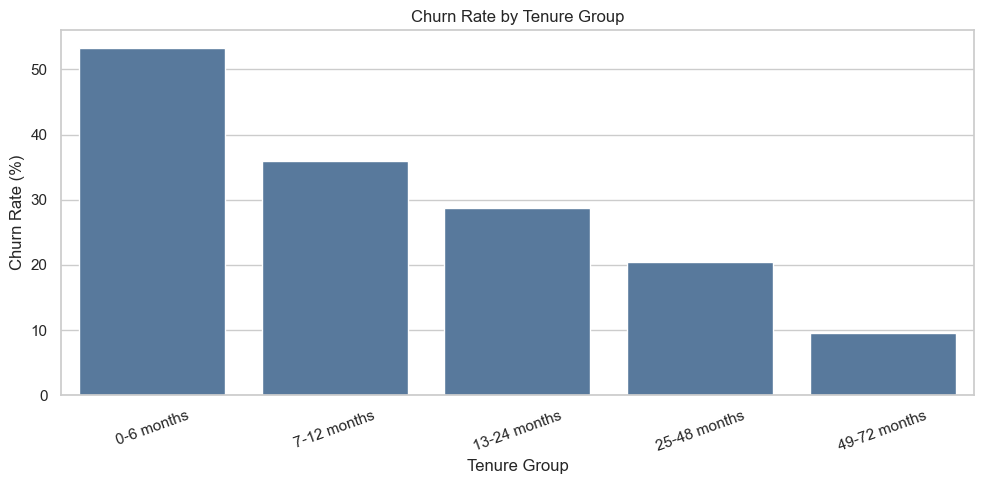

In [41]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=tenure_churn.index.astype(str),
    y=tenure_churn["Churn Rate (%)"].values,
    color="#4C78A8"
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\Churn_rate_by_tenure_group.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [42]:

contract_tenure_churn = pd.pivot_table(
    df,
    index="TenureGroup",
    columns="Contract",
    values="Churn",
    aggfunc=lambda s: (s == "Yes").mean() * 100,
    observed=False
)

print(contract_tenure_churn.round(2))


Contract      Month-to-month  One year  Two year
TenureGroup                                     
0-6 months             55.20     10.53      0.00
7-12 months            42.00     10.59      0.00
13-24 months           37.72      8.12      0.00
25-48 months           32.92     10.62      2.19
49-72 months           26.02     12.93      3.33


In [43]:

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

print(correlation_matrix.round(2))


                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.02            0.22          0.10
tenure                   0.02    1.00            0.25          0.83
MonthlyCharges           0.22    0.25            1.00          0.65
TotalCharges             0.10    0.83            0.65          1.00


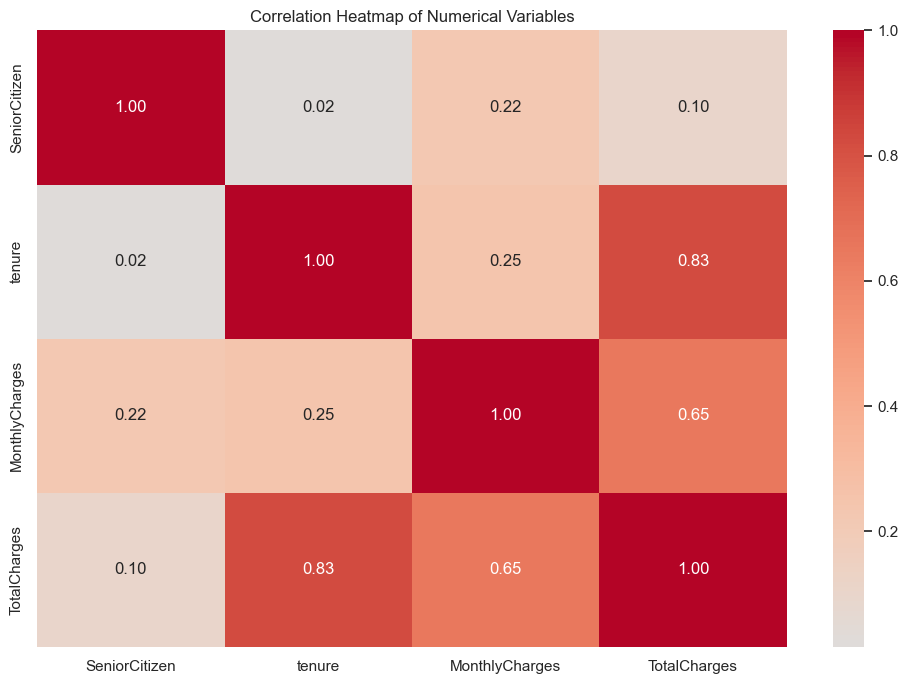

In [44]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout() 
plt.savefig(
    r"D:\Customer-Churn-Analysis\reports\charts\Coorelation_heatmep_of_numeric_variables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [45]:

# Overall churn metrics
overall_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Overall Churn Rate (%)",
        "Average Tenure (Months)",
        "Average Monthly Charges"
    ],
    "Value": [
        len(df),
        (df["Churn"] == "Yes").sum(),
        (df["Churn"] == "No").sum(),
        round((df["Churn"] == "Yes").mean() * 100, 2),
        round(df["tenure"].mean(), 2),
        round(df["MonthlyCharges"].mean(), 2)
    ]
})

display(overall_summary)


,Metric,Value
0,Total Customers,7032.00
1,Churned Customers,1869.00
2,Retained Customers,5163.00
3,Overall Churn Rate (%),26.58
4,Average Tenure (Months),32.42
5,Average Monthly Charges,64.80


In [46]:

segment_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

for column in segment_columns:
    rates = (
        df.groupby(column, dropna=False)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {column}:")
    print(rates.round(2))



Churn rate by Contract:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

Churn rate by InternetService:
InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64

Churn rate by PaymentMethod:
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64

Churn rate by TechSupport:
TechSupport
No                     41.65
Yes                    15.20
No internet service     7.43
Name: Churn, dtype: float64

Churn rate by OnlineSecurity:
OnlineSecurity
No                     41.78
Yes                    14.64
No internet service     7.43
Name: Churn, dtype: float64
